In [575]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm as cm
mpl.rcParams['figure.dpi'] = 300

In [576]:
def condition(A):
    A_11 = A[:-1, :-1]
    A_21 = A[-1:, :-1]
    A_12 = A[:-1, -1:]
    A_22 = A[-1:, -1:]
    A_22i = np.linalg.inv(A_22)
    
    A_transformer = A_12 @ A_22i
    A_bar = A_11 - A_transformer @ A_21
    A_bar_CHOL = np.linalg.cholesky(A_bar)
    
    return A_bar, A_bar_CHOL, A_transformer

In [577]:
L = 123

SIG0 = np.eye(L)
INT  = np.tril(np.ones((L,L)))

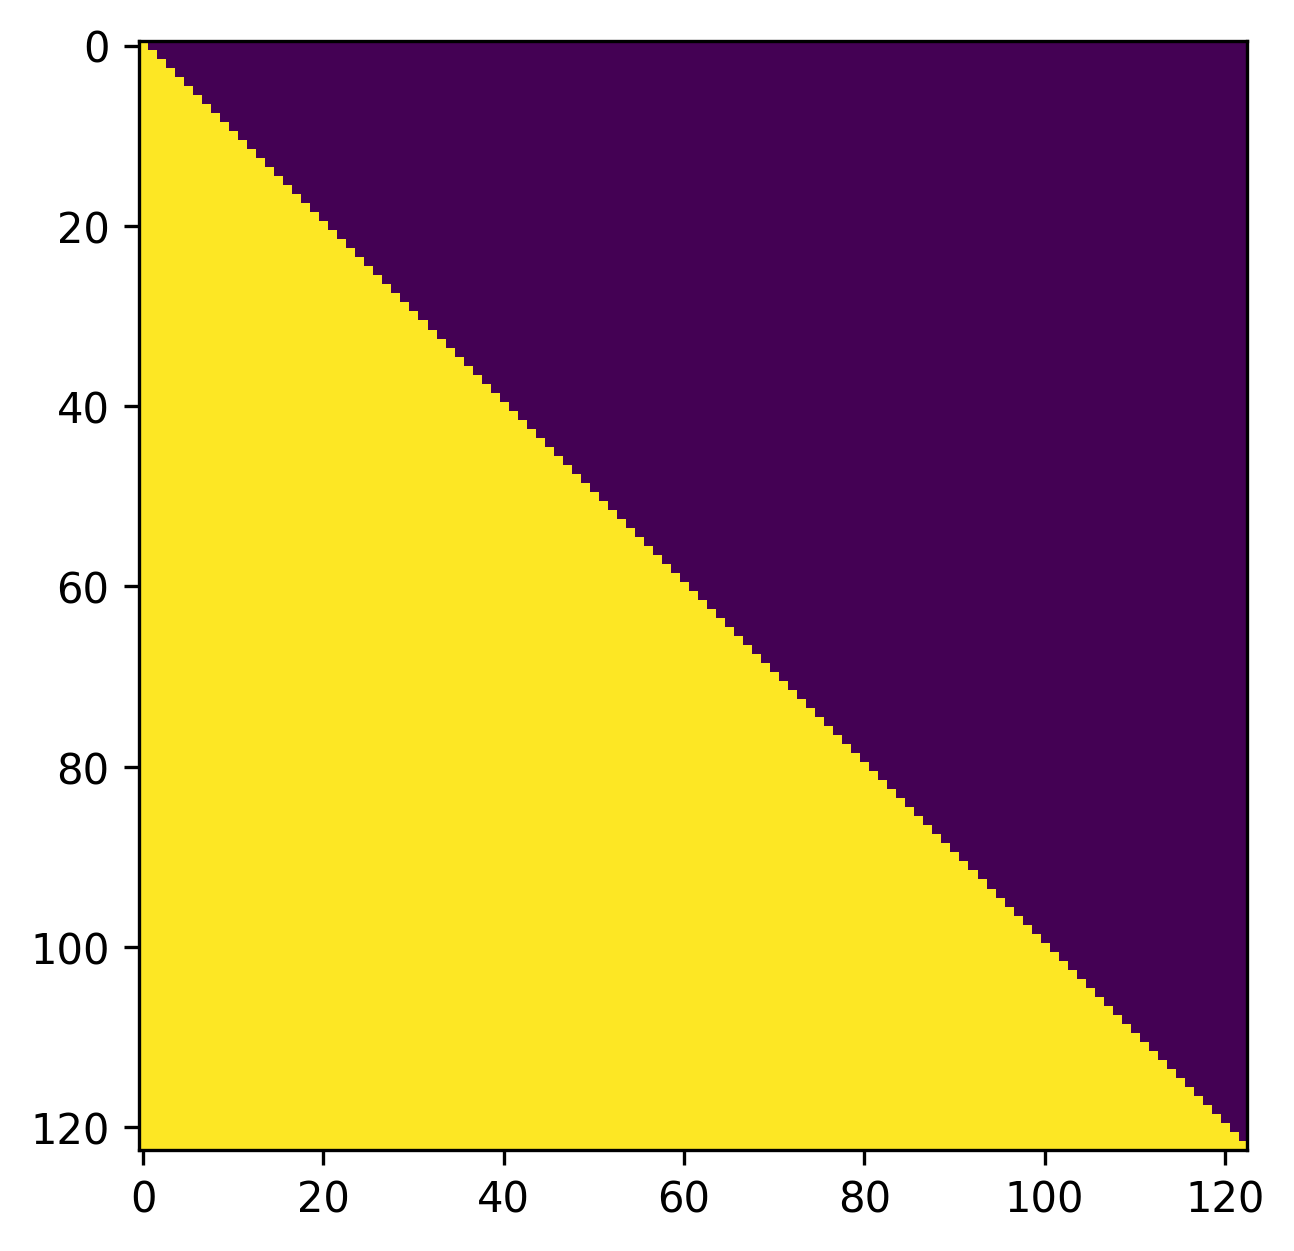

In [579]:
plt.imshow(INT)

In [586]:
SIG1 = INT @ SIG0 @ INT.T

In [587]:
vel = 1

In [588]:
SIG1_bar, SIG1_bar_CHOL, SIG1_transf = condition(SIG1)
MU1_bar = SIG1_transf * vel

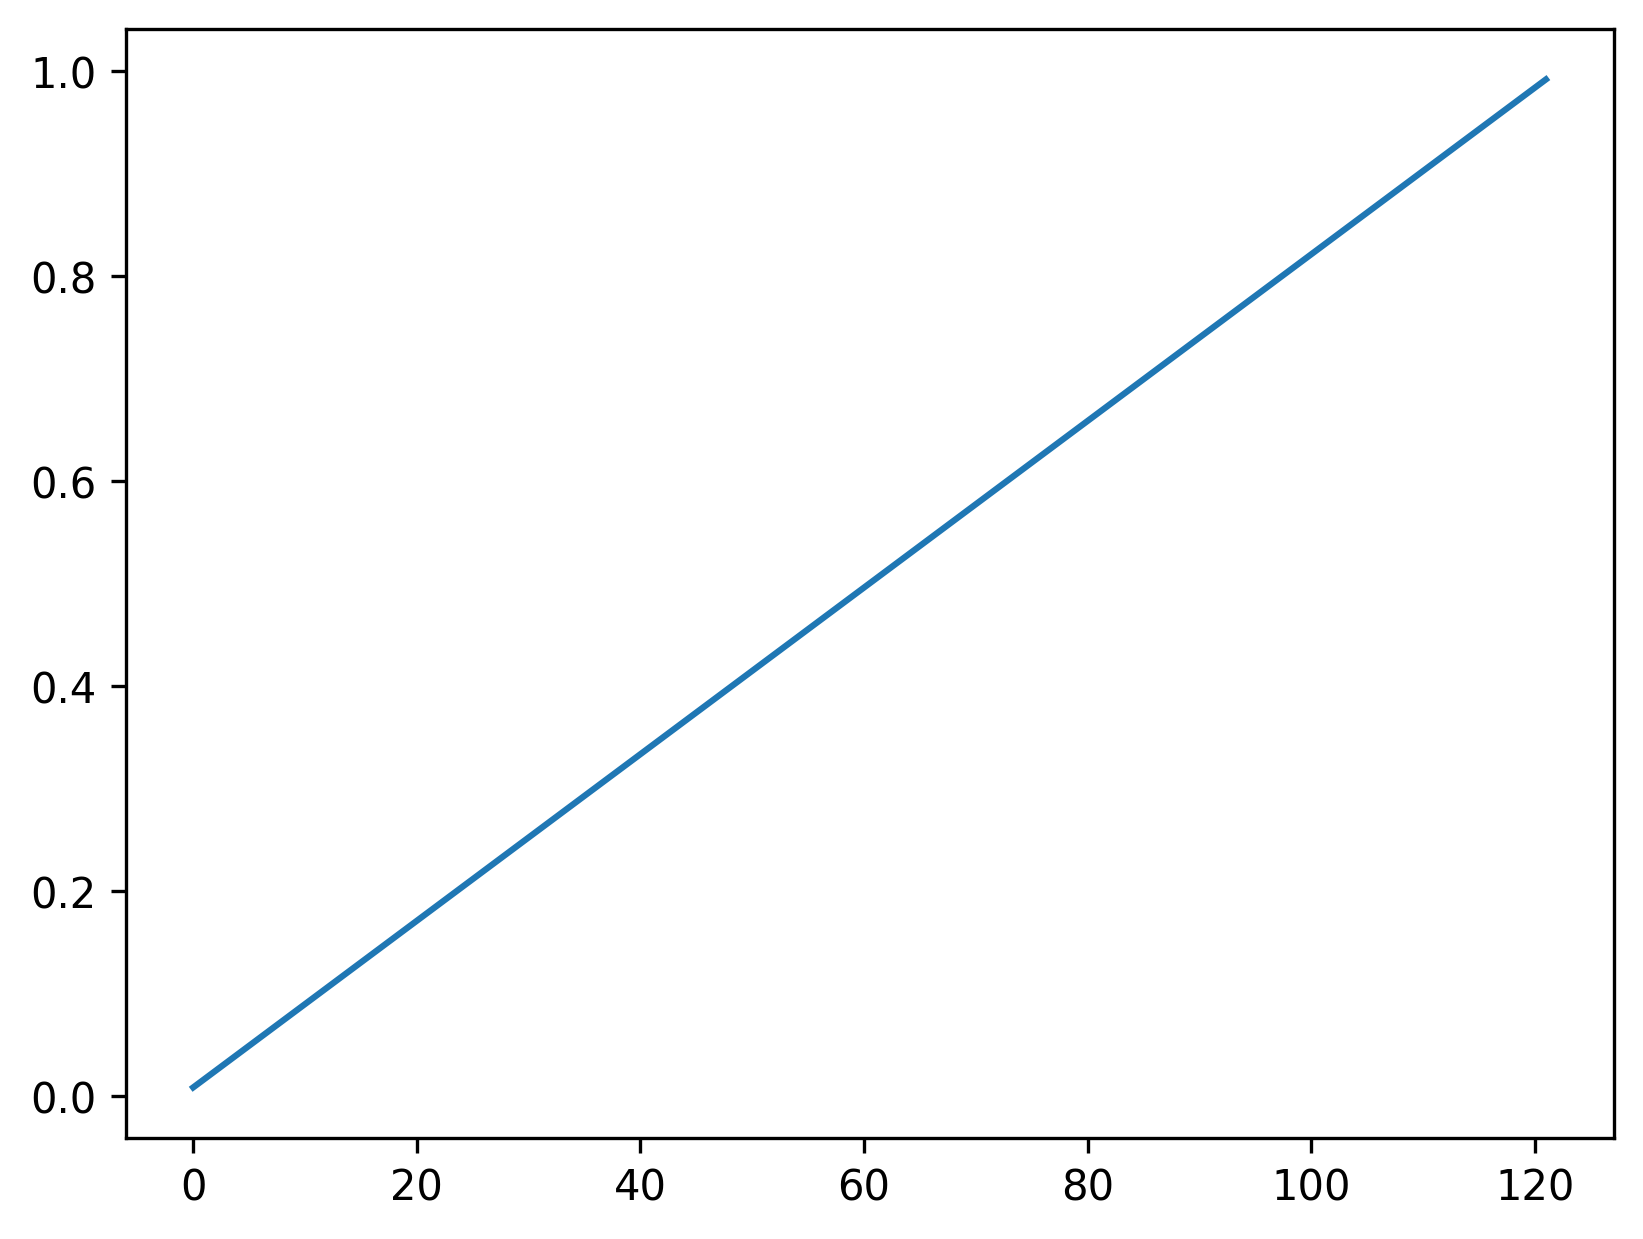

In [589]:
plt.plot(MU1_bar)

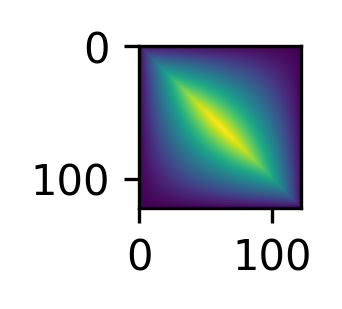

In [626]:
%matplotlib inline
plt.figure(figsize=(1.2,1.2))
plt.imshow(SIG1_bar)
plt.tight_layout()
plt.savefig("img.png", dpi=300, transparent=True)

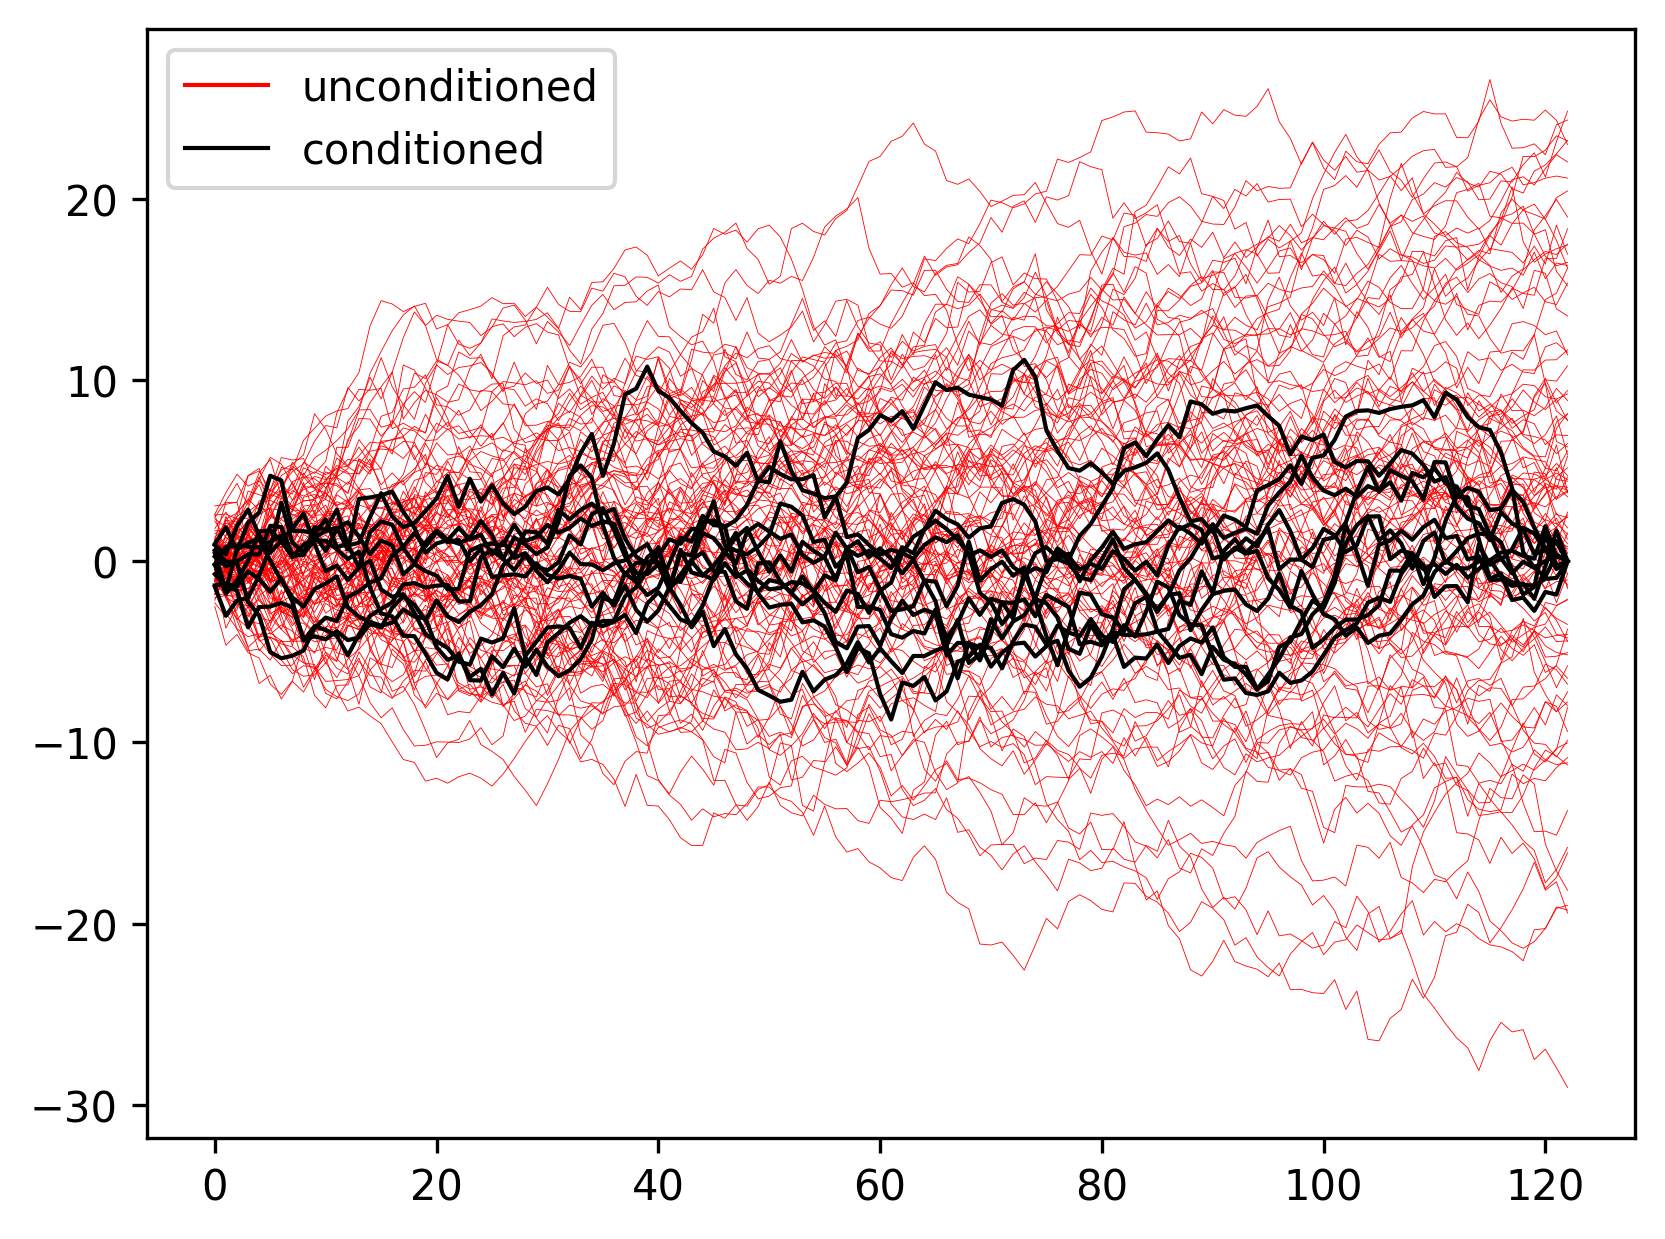

In [615]:
n = 100
w = np.random.randn(L, n)
W = np.linalg.cholesky(SIG1) @ w

plt.plot(W, 'r', linewidth=0.2)
plt.plot([0], 'r', linewidth=1, label='unconditioned')


n = 10
w = np.random.randn(L-1, n)
W = np.pad(SIG1_bar_CHOL @ w, ((0,1),(0,0)))

plt.plot(W, 'k', linewidth=1)
plt.plot([0], 'k', linewidth=1, label='conditioned')
plt.legend()
plt.show()

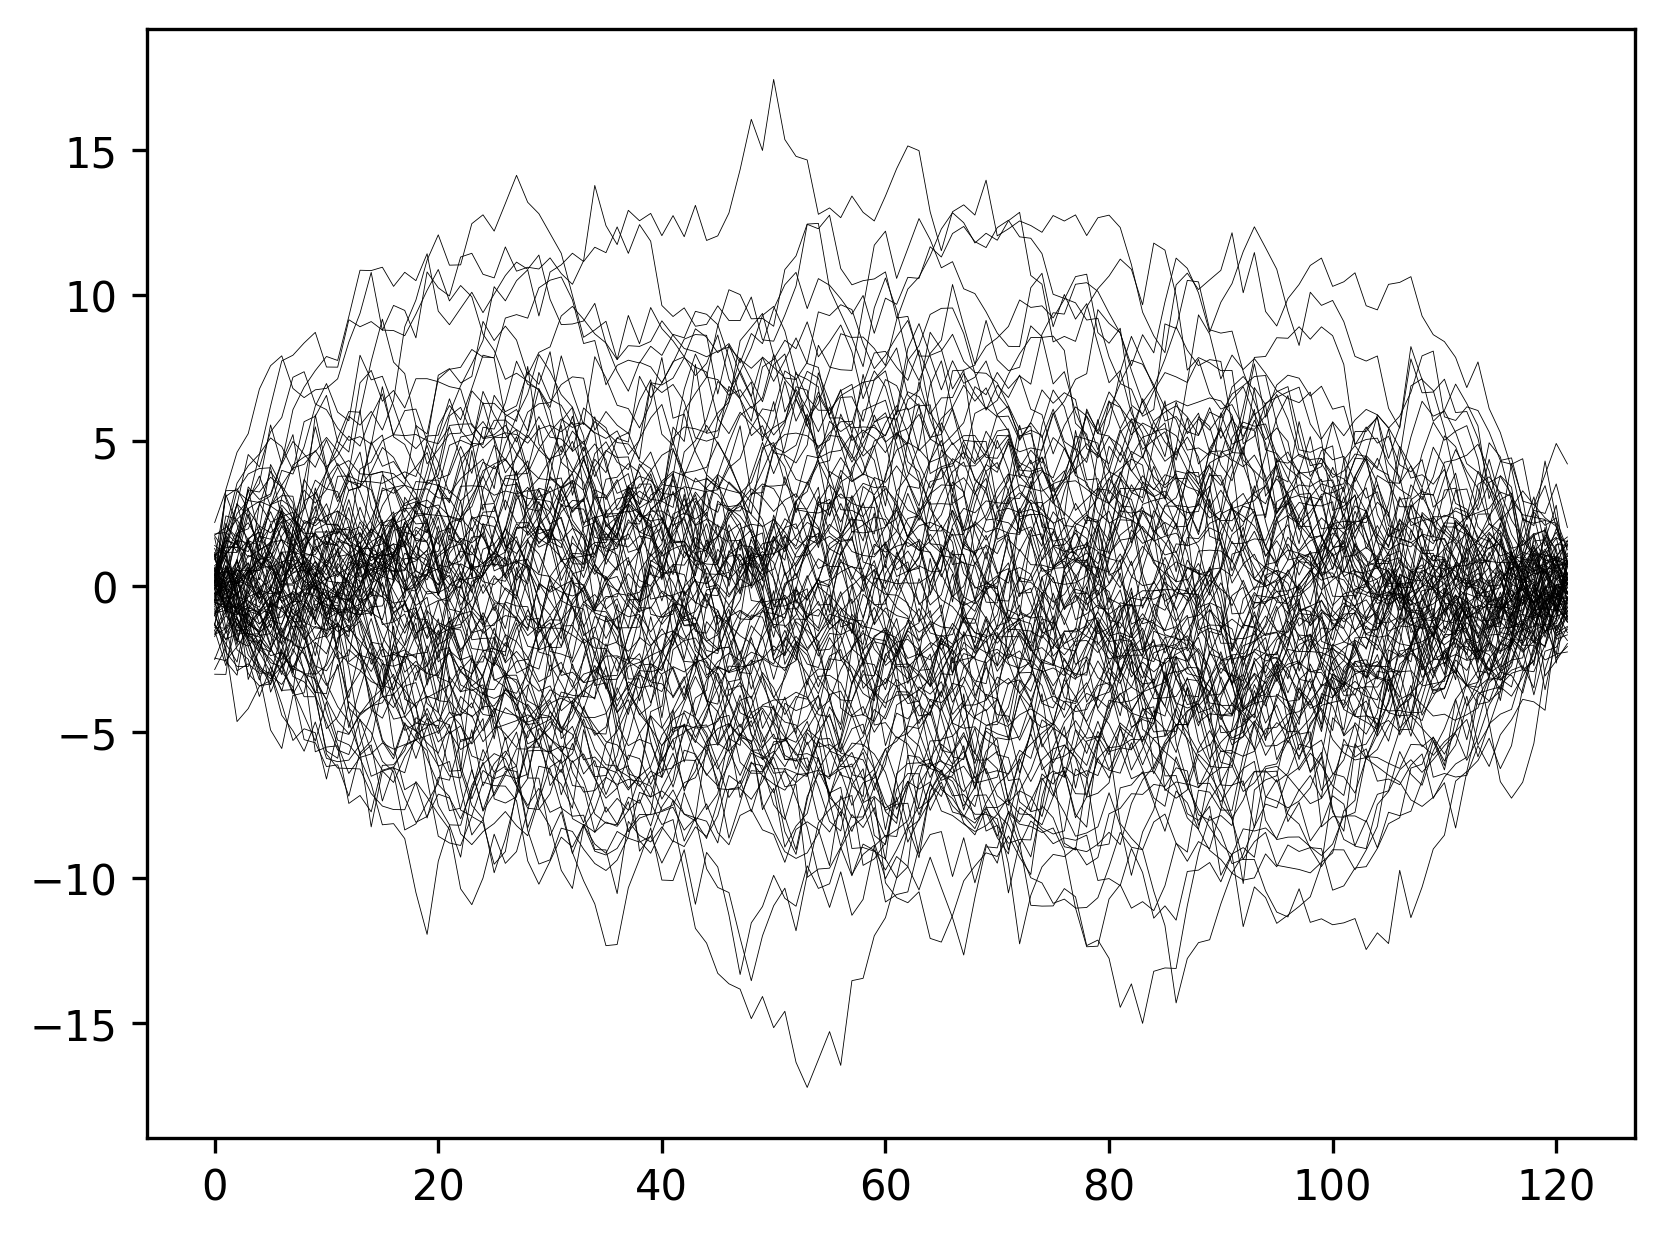

In [593]:
n = 100
w = np.random.randn(L-1, n)
W = SIG1_bar_CHOL @ w

plt.plot(W + MU1_bar*0, 'k', linewidth=0.2)
plt.show()

In [565]:
INT  = np.tril(np.ones((L - 1, L - 1)))
SIG2 = INT @ SIG1_bar @ INT.T

In [566]:
SIG2_bar, SIG2_bar_CHOL, SIG2_transf = condition(SIG2)
MU2 = INT @ MU1_bar

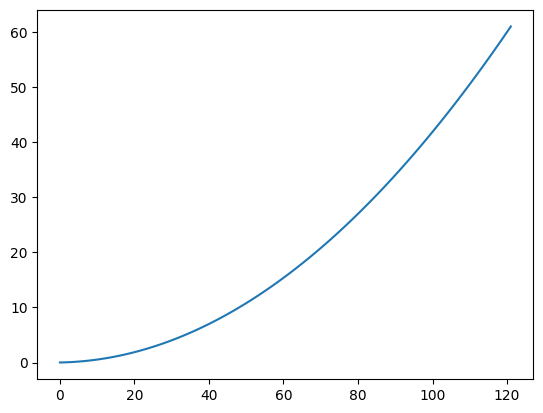

In [567]:
plt.plot(MU2)

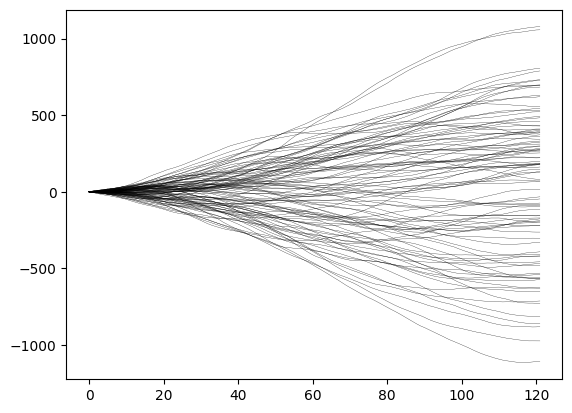

In [568]:
n = 100
w = np.random.randn(L-1, n)
W = np.linalg.cholesky(SIG2) @ w

plt.plot(W + MU2, 'k', linewidth=0.2)
plt.show()

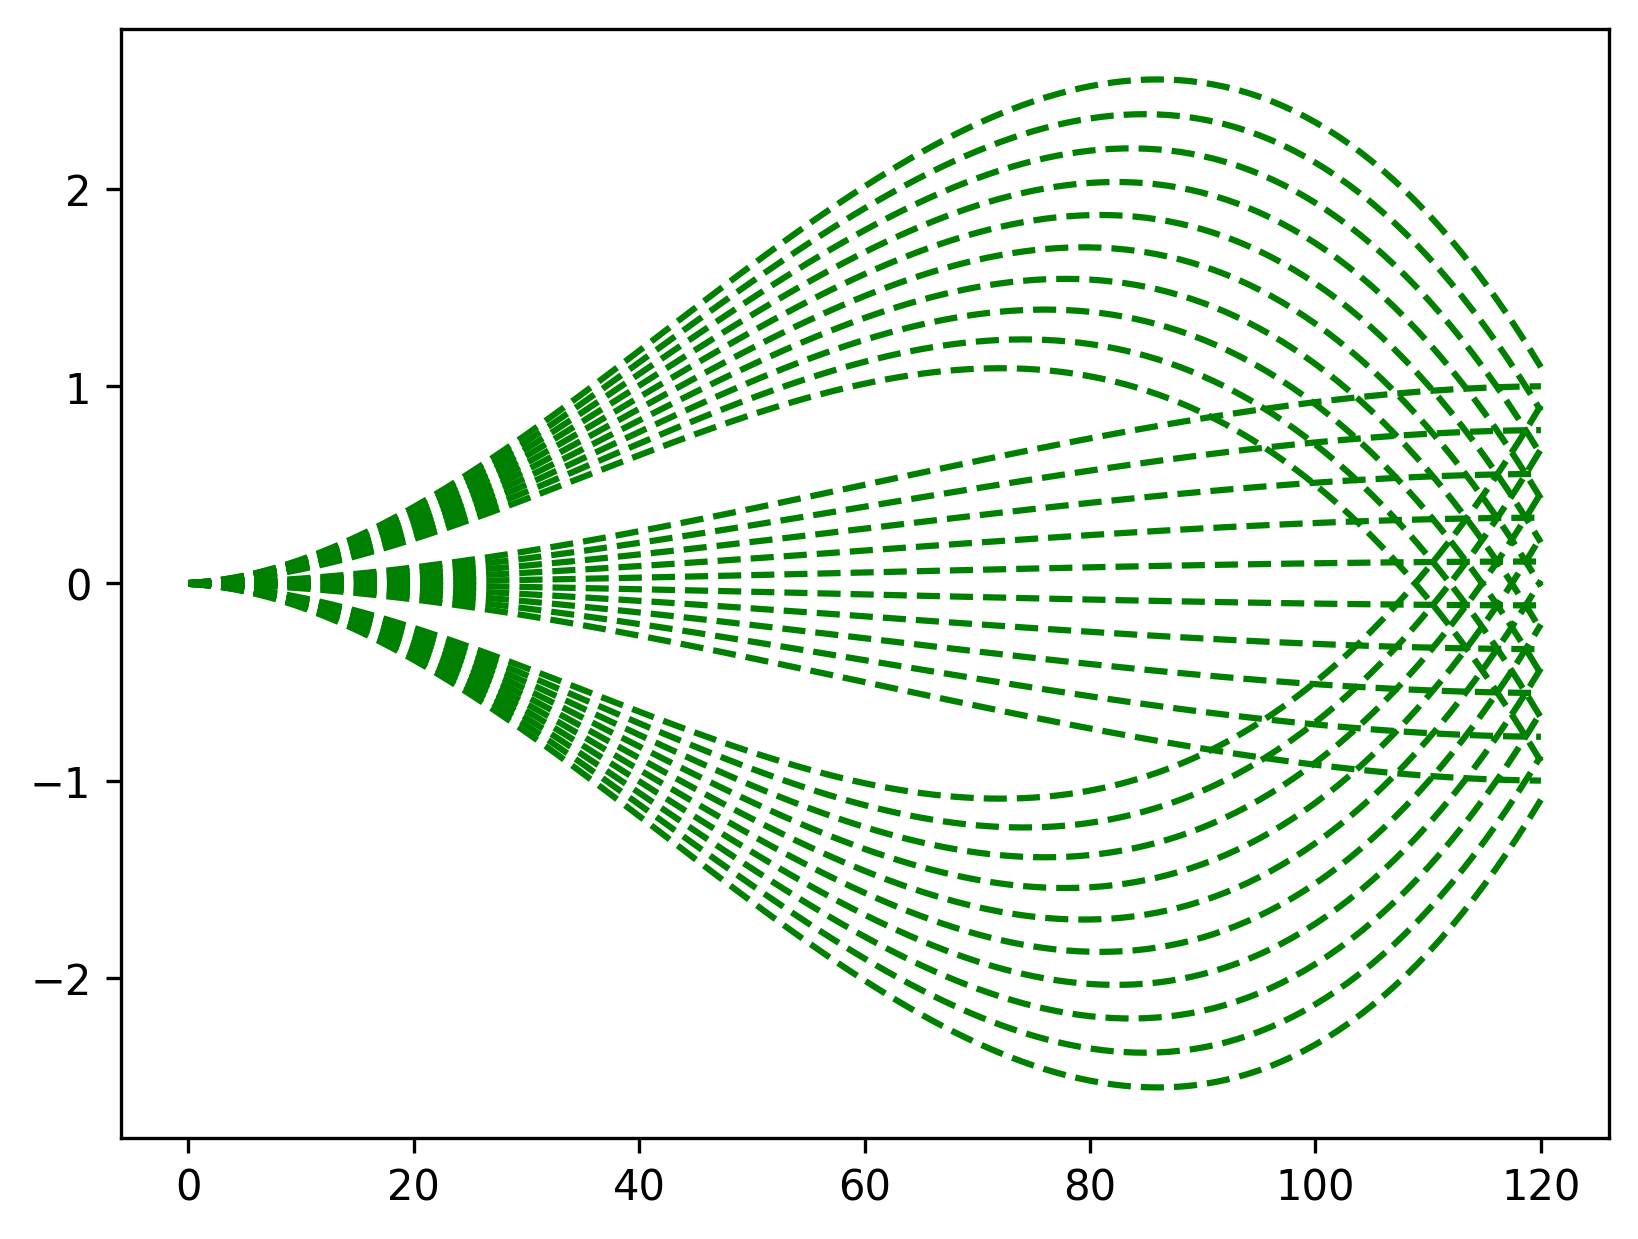

In [641]:
for fin in np.linspace(-1,1,10):
    vel = 0
    MU2_bar = vel * MU2[:-1,:] + SIG2_transf @ (fin -  vel * MU2[-1:,-1:])
    STD2_bar = np.sqrt(np.diagonal(SIG2_bar))
    plt.plot(MU2_bar, '--g')
    
for fin in np.linspace(-1,1,10):
    vel = 0.1
    MU2_bar = vel * MU2[:-1,:] + SIG2_transf @ (fin -  vel * MU2[-1:,-1:])
    STD2_bar = np.sqrt(np.diagonal(SIG2_bar))
    plt.plot(MU2_bar, '--g')
    
for fin in np.linspace(-1,1,10):
    vel = -0.1
    MU2_bar = vel * MU2[:-1,:] + SIG2_transf @ (fin -  vel * MU2[-1:,-1:])
    STD2_bar = np.sqrt(np.diagonal(SIG2_bar))
    plt.plot(MU2_bar, '--g')
plt.show()

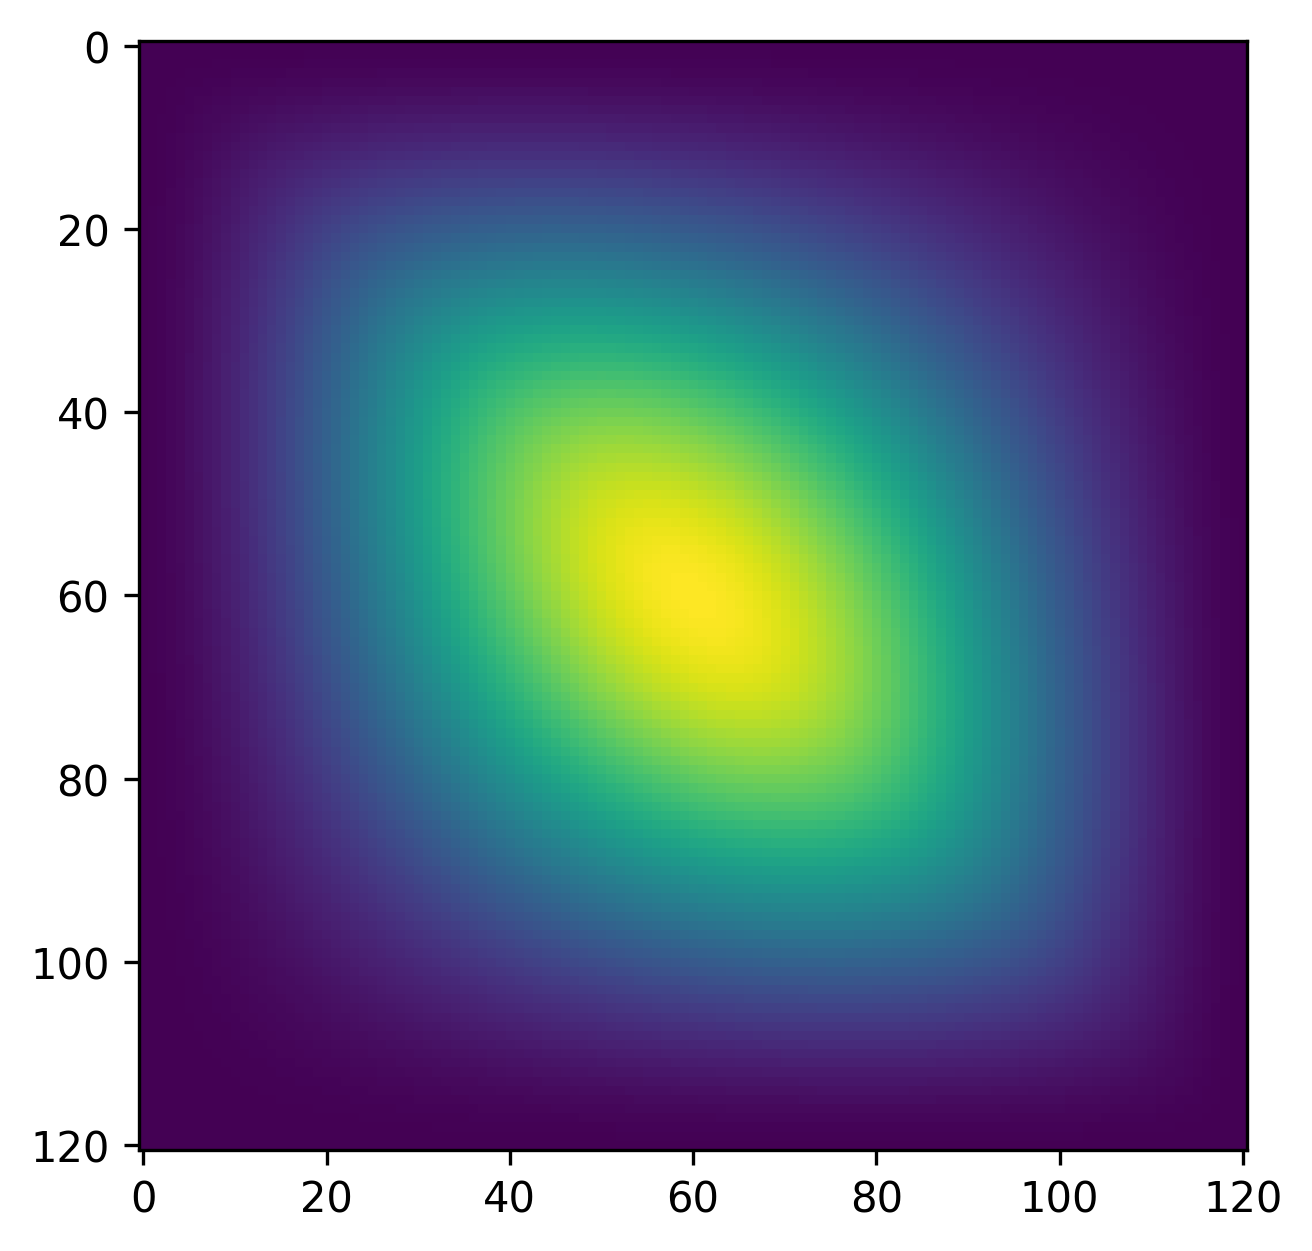

In [642]:
plt.imshow(SIG2_bar)

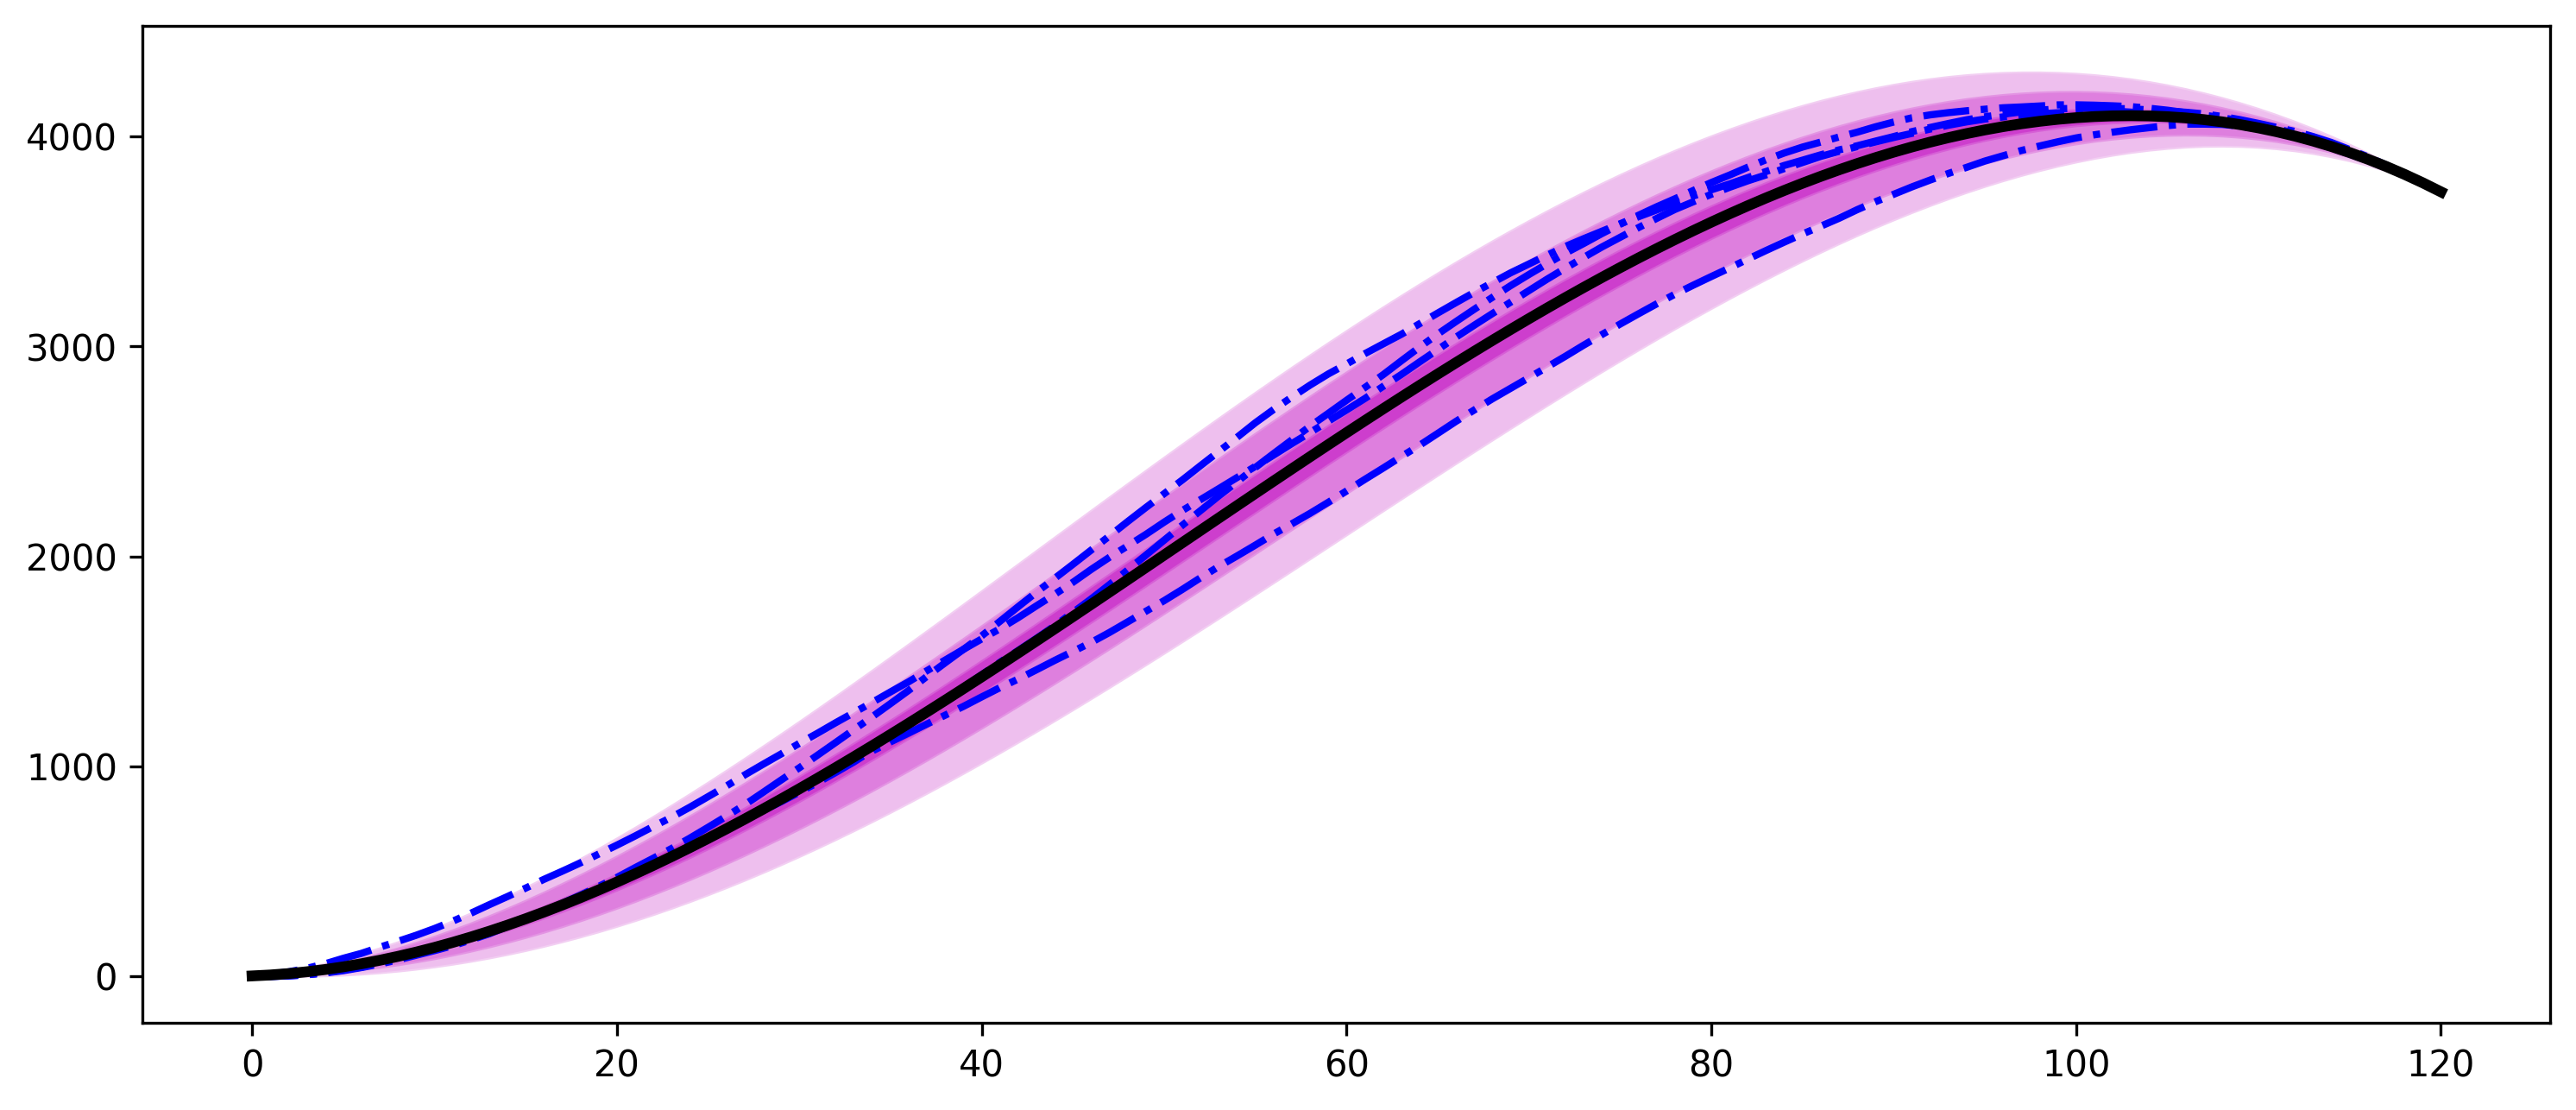

In [673]:
vel = -0.4
fin = 30
MU2_bar = vel * MU2[:-1,:] + SIG2_transf @ (fin -  vel * MU2[-1:,-1:])
STD2_bar = np.sqrt(np.diagonal(SIG2_bar))

n = 4
w = np.random.randn(L-2, n)
W = SIG2_bar_CHOL @ w
plt.figure(figsize=(12,5))
for o in range(3):
    plt.fill_between(np.arange(len(MU2_bar)), (MU2_bar.flatten() * L + (2*o+1) * STD2_bar), (MU2_bar.flatten() * L - (2*o+1) * STD2_bar), color='m', alpha=1/(o+2), edgecolor=(1,1,1))

plt.plot(2*W + MU2_bar * L, '-.b', linewidth=2, alpha=1)
plt.plot(MU2_bar * L, '-k', linewidth=3)
#plt.plot(MU2_bar * L, '--w', linewidth=2)
#plt.plot((MU2_bar.flatten() * L + STD2_bar), '-w', linewidth=1)
#plt.plot((MU2_bar.flatten() * L - STD2_bar), '-w', linewidth=1)
#plt.plot((MU2_bar.flatten() * L + STD2_bar), '--k', linewidth=1)
#plt.plot((MU2_bar.flatten() * L - STD2_bar), '--k', linewidth=1)
plt.show()

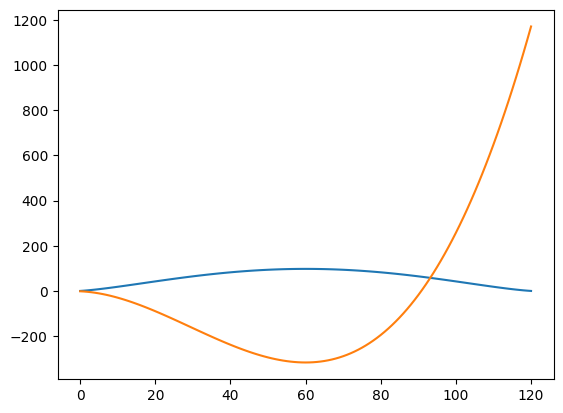

In [572]:
plt.plot(STD2_bar)
plt.plot(MU2_bar*L)